<a href="https://colab.research.google.com/github/miguelmedeiros-arch/DataCience_MKT/blob/main/laboratorio_marketing_python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratório de Ciência de Dados aplicado ao Marketing Digital
**Tema:** análise de dados de campanhas e tomada de decisão · **Base:** `campanhas_marketing_digital.csv` (fictícia)

**Questão central:** o que os dados mostram, por que isso é relevante para o Marketing Digital e que decisão deve ser investigada a partir dos resultados?

## Etapa 1 · Contextualização
**Duas decisões que a equipe de marketing poderia tomar com estes dados**
1. Manter, ampliar, testar ou revisar o investimento em cada canal (Google Ads, Meta Ads, Instagram e LinkedIn Ads).
2. Redistribuir orçamento entre canais conforme o papel de cada um no funil (topo, meio, fundo).

**Hipótese inicial (não é conclusão):** canais de fundo de funil, como a pesquisa de marca no Google Ads, tendem a ter melhor eficiência (CPA e ROAS) do que canais de topo de funil, como o Instagram, mas isso precisa ser verificado nos dados.

## Etapa 2 · Conhecendo e tratando os dados

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.width", 200)

# No Google Colab: se o arquivo não estiver na pasta, descomente as linhas abaixo e envie o CSV.
# from google.colab import files
# files.upload()

df = pd.read_csv("campanhas_marketing_digital.csv", encoding="utf-8-sig")
df.head()

,data,canal,campanha,etapa_funil,investimento,impressoes,alcance,cliques,interacoes,leads,conversoes,receita
0,2026-08-03,Google Ads,Pesquisa Marca,Fundo de funil,1200,52000,41000,2600,310,150.00,58,8700
1,2026-08-03,Meta Ads,Conversao Social,Meio de funil,1000,78000,59000,2340,410,118.00,42,5200
2,2026-08-03,Instagram,Conteudo Impulsionado,Topo de funil,650,92000,68000,1840,520,72.00,18,1800
3,2026-08-03,LinkedIn Ads,Leads B2B,Meio de funil,900,31000,24500,930,145,64.00,16,4800
4,2026-08-10,Google Ads,Pesquisa Marca,Fundo de funil,1250,54000,42500,2862,335,162.00,63,9450


In [ ]:
print("Registros e variáveis (shape):", df.shape)
print()
df.info()

Registros e variáveis (shape): (24, 12)

<class 'pandas.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   data          24 non-null     str    
 1   canal         24 non-null     str    
 2   campanha      24 non-null     str    
 3   etapa_funil   24 non-null     str    
 4   investimento  24 non-null     int64  
 5   impressoes    24 non-null     int64  
 6   alcance       24 non-null     int64  
 7   cliques       24 non-null     int64  
 8   interacoes    24 non-null     int64  
 9   leads         23 non-null     float64
 10  conversoes    24 non-null     int64  
 11  receita       24 non-null     int64  
dtypes: float64(1), int64(7), str(4)
memory usage: 2.4 KB


In [ ]:
print("Valores ausentes por coluna:")
print(df.isna().sum())
print()
print("Linhas duplicadas:", df.duplicated().sum())
print()
print("Categorias de 'canal' (repr mostra espaços escondidos):")
print(df["canal"].apply(repr).value_counts())

Valores ausentes por coluna:
data            0
canal           0
campanha        0
etapa_funil     0
investimento    0
impressoes      0
alcance         0
cliques         0
interacoes      0
leads           1
conversoes      0
receita         0
dtype: int64

Linhas duplicadas: 0

Categorias de 'canal' (repr mostra espaços escondidos):
canal
'Google Ads'      6
'Meta Ads'        6
'LinkedIn Ads'    6
'Instagram'       5
'Instagram '      1
Name: count, dtype: int64


**Problemas de qualidade encontrados**
- `leads` tem **1 valor ausente** (Instagram, 24/08/2026).
- `canal` tem uma **inconsistência categórica**: `'Instagram '` com espaço no fim (10/08/2026).
- `data` está como texto e precisa virar data/hora.
- Não há linhas duplicadas.

In [ ]:
# Tratamento
df["canal"] = df["canal"].str.strip()
df["data"] = pd.to_datetime(df["data"])

# O lead ausente NÃO é substituído por zero: continua NaN e a limitação é registrada.
print(df["canal"].value_counts())
print()
print(df.loc[df["leads"].isna(), ["data", "canal", "campanha", "leads"]])
print()
print("Período:", df["data"].min().date(), "a", df["data"].max().date())

canal
Google Ads      6
Meta Ads        6
Instagram       6
LinkedIn Ads    6
Name: count, dtype: int64

         data      canal               campanha  leads
14 2026-08-24  Instagram  Conteudo Impulsionado    NaN

Período: 2026-08-03 a 2026-09-07


**Por que não trocar o lead ausente por zero?** Zero significaria "medimos e não houve nenhum lead". Aqui o dado simplesmente não foi registrado. Um zero puxaria médias para baixo e distorceria qualquer taxa que use leads.

**Respostas da etapa**
1. **Informações disponíveis:** data, canal, campanha, etapa do funil, investimento, impressões, alcance, cliques, interações, leads, conversões e receita, num total de 24 registros (4 canais × 6 semanas).
2. **Variáveis essenciais para desempenho e eficiência:** `investimento`, `impressoes`, `cliques`, `conversoes` e `receita`.
3. **Problemas de qualidade:** descritos acima.
4. **Perguntas de negócio que a base permite responder:** qual canal tem mais volume, qual é mais eficiente, se há canal com alto investimento e baixo retorno, como o desempenho evolui no tempo e se o gasto acompanha as conversões.

## Etapa 3 · Análise exploratória
**Cuidado:** métricas agregadas são calculadas pela **razão entre somas**, e não pela média simples das taxas por linha.

In [ ]:
# Métricas por registro
df["CTR"] = df["cliques"] / df["impressoes"] * 100
df["taxa_conversao"] = df["conversoes"] / df["cliques"] * 100
df["CPC"] = df["investimento"] / df["cliques"]
df["CPA"] = df["investimento"] / df["conversoes"]
df["ROAS"] = df["receita"] / df["investimento"]

# Exercício 2: Google Ads em 03/08/2026
ex2 = df[(df["canal"] == "Google Ads") & (df["data"] == "2026-08-03")]
ex2.assign(data=ex2["data"].dt.strftime("%d/%m/%Y"))[["data", "canal", "CTR", "taxa_conversao", "CPC", "CPA", "ROAS"]].round(2)

,data,canal,CTR,taxa_conversao,CPC,CPA,ROAS
0,03/08/2026,Google Ads,5.00,2.23,0.46,20.69,7.25


In [ ]:
# Agrupamento por canal usando somas
soma_cols = ["investimento", "impressoes", "alcance", "cliques", "interacoes", "leads", "conversoes", "receita"]
canal = df.groupby("canal")[soma_cols].sum()   # leads soma só os valores presentes (NaN é ignorado)

# Recálculo das métricas sobre os totais
canal["CTR (%)"] = canal["cliques"] / canal["impressoes"] * 100
canal["Taxa conv. (%)"] = canal["conversoes"] / canal["cliques"] * 100
canal["CPC (R$)"] = canal["investimento"] / canal["cliques"]
canal["CPA (R$)"] = canal["investimento"] / canal["conversoes"]
canal["ROAS"] = canal["receita"] / canal["investimento"]

tabela = canal[["investimento", "conversoes", "receita", "CTR (%)", "Taxa conv. (%)", "CPC (R$)", "CPA (R$)", "ROAS"]]
tabela.sort_values("conversoes", ascending=False).round(2)

,investimento,conversoes,receita,CTR (%),Taxa conv. (%),CPC (R$),CPA (R$),ROAS
canal,,,,,,,,
Google Ads,8250,416,62400,5.43,2.20,0.44,19.83,7.56
Meta Ads,7100,296,36950,2.98,1.92,0.46,23.99,5.20
Instagram,4830,128,12800,1.96,1.05,0.40,37.73,2.65
LinkedIn Ads,6500,111,33300,2.89,1.82,1.06,58.56,5.12


In [ ]:
# Ordenações pedidas no roteiro
print("Maior volume de conversões :", canal["conversoes"].idxmax())
print("Maior taxa de conversão    :", canal["Taxa conv. (%)"].idxmax())
print("Menor CPA                  :", canal["CPA (R$)"].idxmin())
print("Maior ROAS                 :", canal["ROAS"].idxmax())
print()
print("Ranking por ROAS:")
print(canal["ROAS"].sort_values(ascending=False).round(2))
print()
print("Ranking por CPA (menor = melhor):")
print(canal["CPA (R$)"].sort_values().round(2))

Maior volume de conversões : Google Ads
Maior taxa de conversão    : Google Ads
Menor CPA                  : Google Ads
Maior ROAS                 : Google Ads

Ranking por ROAS:
canal
Google Ads     7.56
Meta Ads       5.20
LinkedIn Ads   5.12
Instagram      2.65
Name: ROAS, dtype: float64

Ranking por CPA (menor = melhor):
canal
Google Ads     19.83
Meta Ads       23.99
Instagram      37.73
LinkedIn Ads   58.56
Name: CPA (R$), dtype: float64


**Volume × eficiência (Exercício 3)**
1. **Maior volume de conversões:** Google Ads (416).
2. **Maior taxa de conversão:** Google Ads (2,20%).
3. **Maior ROAS:** Google Ads (7,56).
4. **Menor CPA:** Google Ads (R$ 19,83).
5. **Alto investimento e baixo retorno relativo:** há dois candidatos. O **LinkedIn Ads** tem o maior CPA (R$ 58,56) e o CPC mais que o dobro dos demais (R$ 1,06), com o terceiro maior investimento. O **Instagram** tem o menor ROAS (2,65) e a menor taxa de conversão (1,05%), mas é um canal de topo de funil, então julgá-lo só por ROAS é injusto.

Neste caso o canal de maior volume também é o mais eficiente, mas essa coincidência não vale como regra: volume e eficiência são perguntas diferentes.

## Etapa 4 · Visualizações

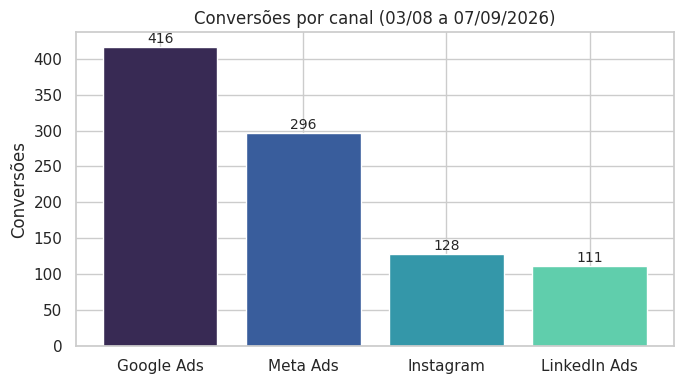

In [ ]:
ordem = canal["conversoes"].sort_values(ascending=False).index
paleta = dict(zip(["Google Ads", "Meta Ads", "Instagram", "LinkedIn Ads"], sns.color_palette("mako", 4)))

# Gráfico 1: barras, conversões por canal
fig, ax = plt.subplots(figsize=(7, 4))
vals = canal.loc[ordem, "conversoes"]
ax.bar(vals.index, vals.values, color=[paleta[c] for c in vals.index])
for i, v in enumerate(vals.values):
    ax.text(i, v + 6, f"{v:,.0f}", ha="center", fontsize=10)
ax.set_title("Conversões por canal (03/08 a 07/09/2026)")
ax.set_ylabel("Conversões")
ax.set_xlabel("")
plt.tight_layout(); plt.show()

**Gráfico 1 · Conversões por canal**
- **Padrão:** o Google Ads soma 416 conversões, cerca de 44% das 951 totais, e o LinkedIn Ads soma 111.
- **Relevância:** mostra onde está a escala. É o ponto de partida para decidir onde manter ou ampliar investimento.
- **Ressalva:** volume não mede eficiência. Os canais também tiveram investimentos diferentes, então é preciso olhar CPA e ROAS.

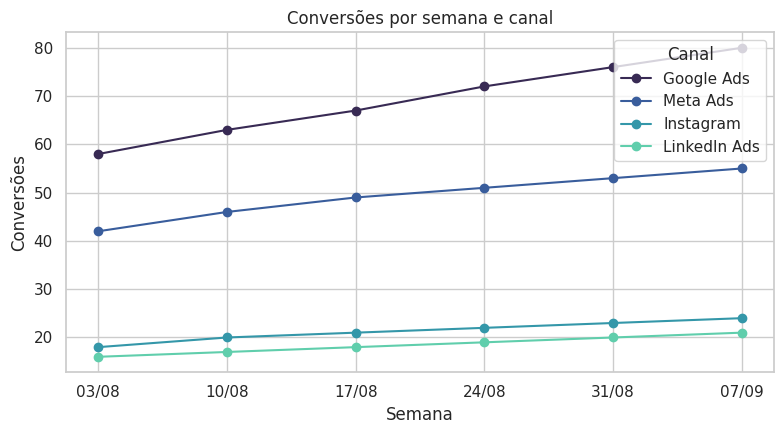

In [ ]:
# Gráfico 2: linha, conversões ao longo do tempo por canal
fig, ax = plt.subplots(figsize=(8, 4.5))
tempo = df.pivot_table(index="data", columns="canal", values="conversoes", aggfunc="sum")
for c in ordem:
    ax.plot(tempo.index, tempo[c], marker="o", label=c, color=paleta[c])
ax.set_title("Conversões por semana e canal")
ax.set_ylabel("Conversões")
ax.set_xlabel("Semana")
ax.set_xticks(tempo.index)
ax.set_xticklabels([d.strftime("%d/%m") for d in tempo.index])
ax.legend(title="Canal")
plt.tight_layout(); plt.show()

**Gráfico 2 · Conversões ao longo do tempo**
- **Padrão:** as conversões cresceram semana a semana em **todos** os canais. O Google Ads foi de 58 para 80 e o Meta Ads de 42 para 55.
- **Relevância:** indica que a operação está escalando, e a ordem entre os canais se mantém estável.
- **Ressalva:** o investimento também subiu em todos os canais no mesmo período, então não dá para separar o efeito do tempo do efeito do gasto. Só seis pontos por canal.

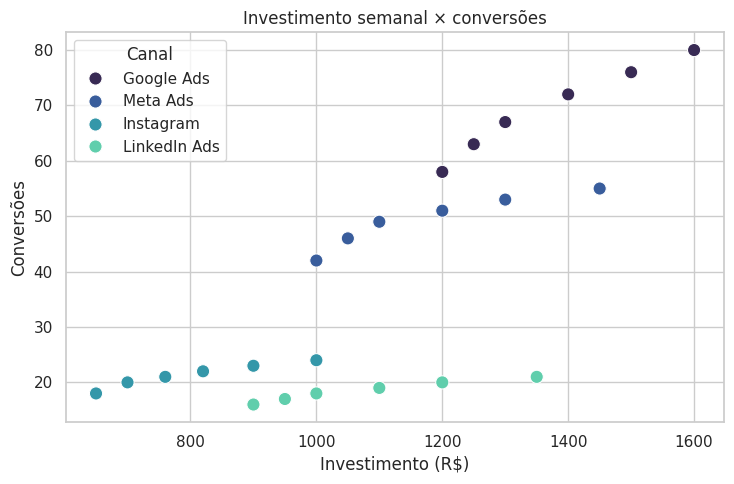

Correlação geral investimento x conversões: 0.79

Correlação por canal:
canal
Google Ads     0.98
Instagram      0.97
LinkedIn Ads   0.98
Meta Ads       0.94
dtype: float64


In [ ]:
# Gráfico 3: dispersão, investimento x conversões, canal identificado
fig, ax = plt.subplots(figsize=(7.5, 5))
sns.scatterplot(data=df, x="investimento", y="conversoes", hue="canal", hue_order=list(ordem),
                palette=paleta, s=90, ax=ax)
ax.set_title("Investimento semanal × conversões")
ax.set_xlabel("Investimento (R$)")
ax.set_ylabel("Conversões")
ax.legend(title="Canal")
plt.tight_layout(); plt.show()

print("Correlação geral investimento x conversões:", round(df["investimento"].corr(df["conversoes"]), 2))
print()
print("Correlação por canal:")
print(df.groupby("canal").apply(lambda g: g["investimento"].corr(g["conversoes"]), include_groups=False).round(2))

**Gráfico 3 · Investimento × conversões**
- **Padrão:** a correlação geral é 0,79. Dentro de cada canal fica entre 0,94 e 0,98. Cada canal forma uma "nuvem" própria, e o Google Ads converte mais por real investido.
- **Relevância:** ajuda a ver a inclinação de cada canal, isto é, quantas conversões cada real adicional parece acompanhar.
- **Ressalva:** correlação não prova causalidade. Investimento e conversões subiram juntos ao longo do tempo, e outros fatores (sazonalidade, criativos, demanda) podem ter mudado junto.

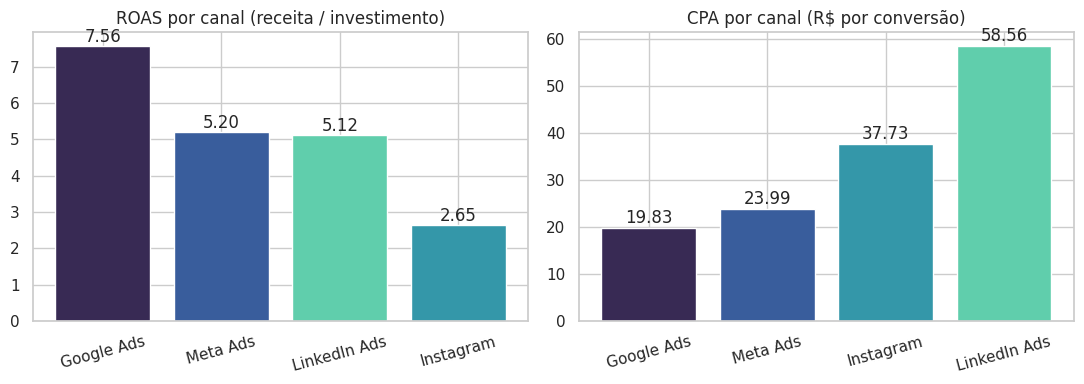

In [ ]:
# Gráfico 4 (opcional): ROAS e CPA por canal
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
r = canal["ROAS"].sort_values(ascending=False)
axes[0].bar(r.index, r.values, color=[paleta[c] for c in r.index])
axes[0].set_title("ROAS por canal (receita / investimento)")
for i, v in enumerate(r.values): axes[0].text(i, v + 0.1, f"{v:.2f}", ha="center")
a = canal["CPA (R$)"].sort_values()
axes[1].bar(a.index, a.values, color=[paleta[c] for c in a.index])
axes[1].set_title("CPA por canal (R$ por conversão)")
for i, v in enumerate(a.values): axes[1].text(i, v + 1, f"{v:.2f}", ha="center")
for ax in axes: ax.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

**Gráfico 4 · ROAS e CPA**
- **Padrão:** o Google Ads lidera nas duas medidas (ROAS 7,56 e CPA R$ 19,83). O LinkedIn tem o pior CPA (R$ 58,56) e o Instagram o pior ROAS (2,65).
- **Ressalva:** ROAS não é lucro nem ROI, porque a base não traz margem, custos, impostos ou atribuição multicanal.

In [ ]:
# Apoio ao Insight: ROAS e CPA semanais por canal
sem = df.groupby(["canal", "data"])[["investimento", "receita", "conversoes"]].sum()
sem["ROAS"] = sem["receita"] / sem["investimento"]
sem["CPA"] = sem["investimento"] / sem["conversoes"]
roas_sem = sem["ROAS"].unstack("canal")
roas_sem.index = roas_sem.index.strftime("%d/%m")
print("ROAS por semana:")
print(roas_sem.round(2))
print()
print("Variação do ROAS, primeira x última semana:")
print(((roas_sem.iloc[-1] / roas_sem.iloc[0] - 1) * 100).round(1).astype(str) + "%")

ROAS por semana:
canal  Google Ads  Instagram  LinkedIn Ads  Meta Ads
data                                                
03/08        7.25       2.77          5.33      5.20
10/08        7.56       2.86          5.37      5.48
17/08        7.73       2.76          5.40      5.57
24/08        7.71       2.68          5.18      5.31
31/08        7.60       2.56          5.00      5.10
07/09        7.50       2.40          4.67      4.74

Variação do ROAS, primeira x última semana:
canal
Google Ads        3.4%
Instagram       -13.3%
LinkedIn Ads    -12.5%
Meta Ads         -8.8%
dtype: str


## Etapa 5 · Insights e recomendações
Estrutura: **evidência → interpretação → decisão proposta → forma de validação.**

### Três insights
- **Resultado positivo:** o Google Ads combina escala e eficiência (416 conversões, CPA R$ 19,83, ROAS 7,56) e seu ROAS ainda subiu de 7,25 para 7,50 entre a primeira e a última semana (+3%).
- **Resultado que merece atenção:** o LinkedIn Ads tem CPA de R$ 58,56, cerca de 3 vezes o do Google Ads, e CPC de R$ 1,06. Seu ROAS caiu de 5,33 para 4,67 (−12%).
- **Oportunidade:** o Instagram tem o maior alcance (449.900) e o maior número de impressões (620.000), mas a menor taxa de conversão (1,05%). Melhorar a passagem de clique para conversão pode render mais do que aumentar o gasto.

**Hipótese explicativa (a validar):** Meta Ads, Instagram e LinkedIn mostram ROAS em queda enquanto o investimento sobe (−9%, −13% e −12% entre a primeira e a última semana, respectivamente), o que sugere **retorno marginal decrescente**. Outra explicação possível é a saturação do público. Nenhuma das duas está provada.

### Duas recomendações testáveis
**Recomendação 1 · Testar aumento controlado no Google Ads**
- *Evidência:* ROAS 7,56 e CPA R$ 19,83, os melhores da base, com ROAS estável ao longo das semanas.
- *Interpretação:* é o canal mais eficiente, mas a campanha é de pesquisa de marca, que capta quem já conhece a empresa. Parte do resultado pode não ser incremental.
- *Decisão:* elevar o orçamento de forma gradual (por exemplo, +10% ao longo de algumas semanas) em vez de remanejar tudo de uma vez.
- *Validação:* teste de incrementalidade com grupo de controle (por região ou por período) e acompanhamento de CPA e ROAS. Se o CPA subir muito, o canal está saturando.

**Recomendação 2 · Revisar o LinkedIn Ads antes de ampliar**
- *Evidência:* CPA R$ 58,56, CPC R$ 1,06 e ROAS em queda (−12%).
- *Interpretação:* o canal custa mais por clique e por conversão. Pode ser um custo natural de B2B, com leads de maior valor, o que a base não permite afirmar.
- *Decisão:* manter o investimento, testar variações de público e criativo e definir um CPA-alvo antes de qualquer ampliação.
- *Validação:* teste A/B de criativos e segmentações e comparação do valor por cliente (LTV ou receita por lead) entre canais.

## Etapa 6 · Exercícios complementares
### Exercício 1 · Diagnóstico
- **Registros e variáveis:** 24 registros e 12 variáveis.
- **Classificação:** `canal` é categórica nominal, `investimento` é numérica contínua, `data` é temporal e `conversoes` é numérica discreta.
- **Ausência:** lead do Instagram em 24/08. **Inconsistência:** `'Instagram '` com espaço no fim.

### Exercício 4 · Tendência e associação

In [ ]:
# a) As conversões aumentam com o tempo em todos os canais?
aumenta = tempo.diff().dropna().gt(0).all()
print("Conversões crescem toda semana?")
print(aumenta)
print()
# b) Correlação investimento x conversões
print("b) Correlação geral:", round(df["investimento"].corr(df["conversoes"]), 2))

Conversões crescem toda semana?
canal
Google Ads      True
Instagram       True
LinkedIn Ads    True
Meta Ads        True
dtype: bool

b) Correlação geral: 0.79


**c) Por que correlação não prova causalidade?** Duas variáveis podem se mover juntas por causa de um terceiro fator (sazonalidade, mudança de criativo, aumento de demanda) ou porque uma coisa acompanha a outra no tempo. Só um experimento controlado, como um teste com grupo de controle, indica se o investimento adicional *causou* as conversões.

## Conclusão
A análise de 24 registros semanais (03/08 a 07/09/2026) mostra que o Google Ads lidera em volume (416 conversões), taxa de conversão (2,20%), CPA (R$ 19,83) e ROAS (7,56). O Meta Ads vem em seguida, com ROAS de 5,20. O LinkedIn Ads tem o maior CPA (R$ 58,56) e o Instagram o menor ROAS (2,65), embora atue no topo do funil. O ROAS caiu em Meta, Instagram e LinkedIn ao longo das semanas, o que sugere retorno decrescente, hipótese que precisa de teste. Recomenda-se testar um aumento gradual no Google Ads, com grupo de controle, e revisar o LinkedIn antes de ampliá-lo. A base não traz margem, custos nem atribuição multicanal, então o ROAS não equivale a lucro e nenhuma causalidade foi comprovada.

## Limitações
- Base **fictícia** com apenas 24 linhas (4 canais × 6 semanas): poucos pontos para tendências.
- O lead do Instagram em 24/08 está ausente e foi mantido como `NaN`. O total de leads do Instagram está subestimado, e por isso não se calculou taxa lead→conversão.
- ROAS **não é lucro nem ROI**: faltam margem, custos operacionais, impostos e atribuição multicanal.
- "Pesquisa Marca" capta público que já conhece a marca, então parte do ROAS do Google Ads pode não ser incremental.
- Não há dados de novos clientes, recorrência, LTV, dispositivo, público ou criativo.
- Padrões observados são correlações: nenhuma relação causal foi testada.

## Ticket de saída
> Antes de recomendar uma mudança de orçamento, eu verificaria **se o resultado de cada canal é incremental (com um teste de controle)**, porque **ROAS e CPA altos podem refletir demanda que já existia, e não o efeito do investimento**.